# Chapter 12: Variational integrators and collocation

Reproduce the chapter's examples and start its exercises: three ways to step a pendulum,
the discrete Hamilton's principle, the Lie group variational integrator for the 3D
pendulum, the explicit exponential update and its energy drift, the step on the sphere,
and a reorientation transcribed two ways and solved with SciPy.

Only NumPy, SciPy and Matplotlib are needed. Notation: $R$ maps body to world,
$R_{k+1} = R_k \exp(h\,\Omega_k^\wedge)$, $p_k$ is the discrete momentum in the body
frame, $h$ the time step.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize

G = 9.81
E3 = np.array([0.0, 0.0, 1.0])
I3 = np.eye(3)


def hat(v):
    return np.array([[0.0, -v[2], v[1]], [v[2], 0.0, -v[0]], [-v[1], v[0], 0.0]])


def vee(M):
    return np.array([M[2, 1], M[0, 2], M[1, 0]])


def expm_so3(w):
    """exp(hat(w)) by Rodrigues' formula."""
    th = np.linalg.norm(w)
    if th < 1e-10:
        return I3 + hat(w)
    K = hat(w / th)
    return I3 + np.sin(th) * K + (1 - np.cos(th)) * K @ K


def log_so3(R):
    th = np.arccos(np.clip(0.5 * (np.trace(R) - 1), -1, 1))
    v = vee(R - R.T) / 2
    return v if th < 1e-9 else th / np.sin(th) * v


def dexpinv(th, w):
    """theta_dot for R = R_k exp(hat(theta)) and body rate w."""
    t = np.linalg.norm(th)
    if t < 1e-6:
        return w + 0.5 * np.cross(th, w)
    c = (1 - 0.5 * t / np.tan(0.5 * t)) / t**2
    return w + 0.5 * np.cross(th, w) + c * np.cross(th, np.cross(th, w))

## 1. Three ways to take a step

A planar pendulum with $m = 1$ kg, $l = 1$ m, released from rest at 60°, stepped with
$h = 0.05$ s for 10 s. With these values the momentum is $p = \dot\theta$.

explicit Euler  energy 4.905 J -> 28.498 J, range [4.905, 29.864]
implicit Euler  energy 4.905 J -> 0.046 J, range [0.046, 4.905]
Störmer-Verlet  energy 4.905 J -> 4.891 J, range [4.877, 4.905]


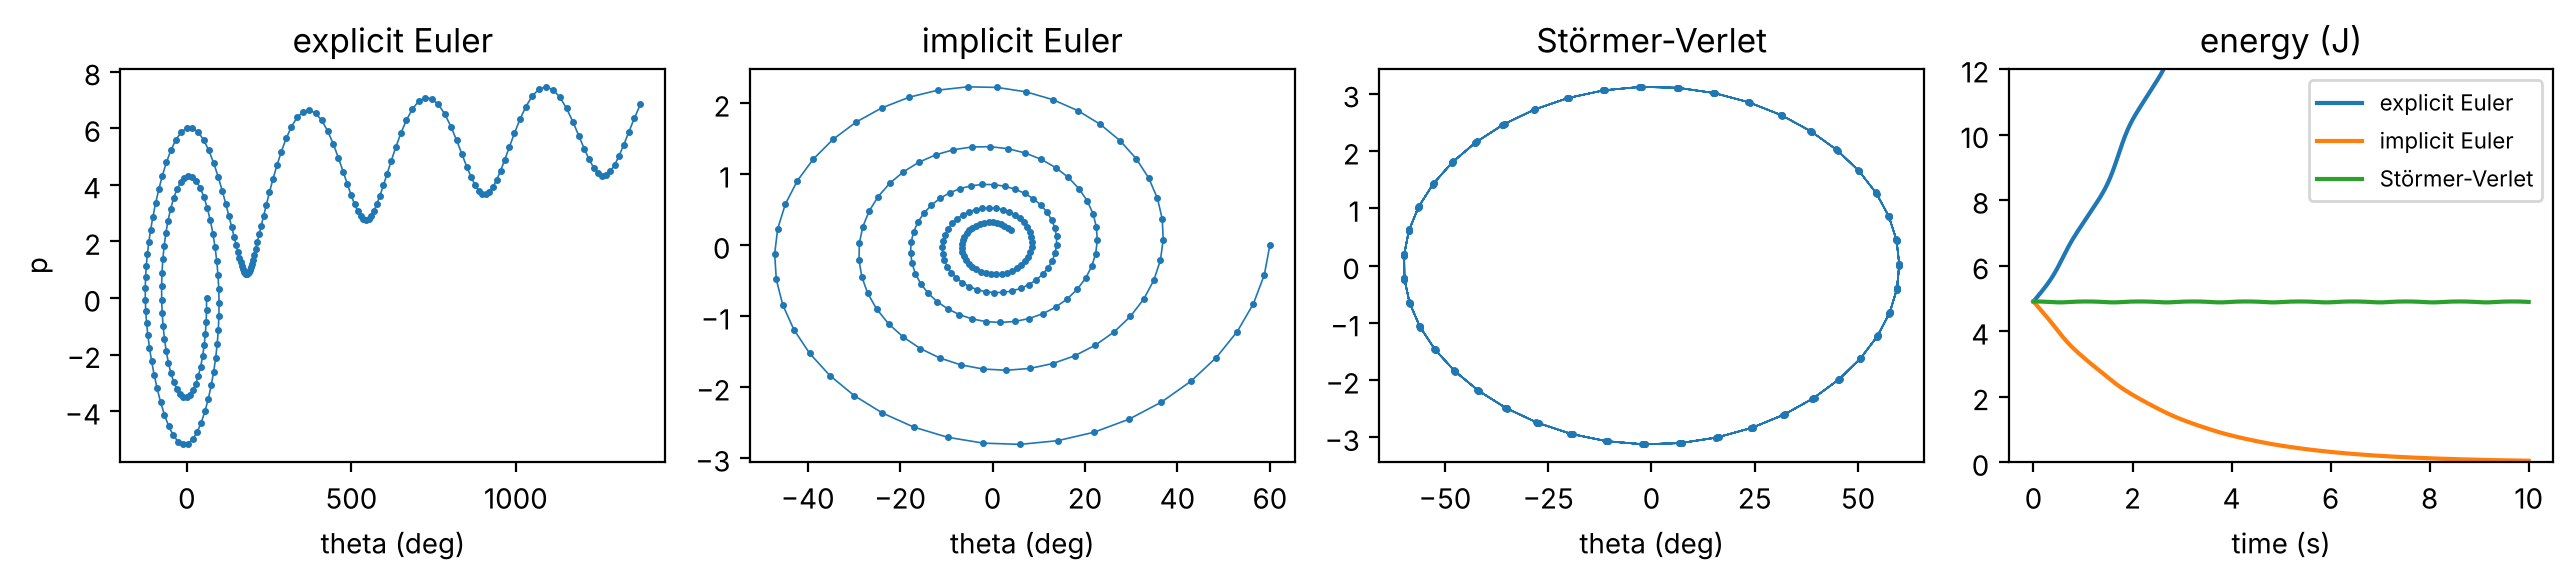

In [2]:
def explicit_euler(th, p, h):
    return th + h * p, p - h * G * np.sin(th)


def implicit_euler(th, p, h):
    th1 = th
    for _ in range(50):                       # Newton on the implicit equation
        th1 -= (th1 - th - h * (p - h * G * np.sin(th1))) / (1 + h * h * G * np.cos(th1))
    return th1, p - h * G * np.sin(th1)


def verlet(th, p, h):
    ph = p - 0.5 * h * G * np.sin(th)         # half kick
    th1 = th + h * ph                         # drift
    return th1, ph - 0.5 * h * G * np.sin(th1)


def run(step, th0, p0, h, n):
    z = np.empty((n + 1, 2))
    z[0] = th0, p0
    for k in range(n):
        z[k + 1] = step(*z[k], h)
    return z


def energy(z):
    return 0.5 * z[:, 1] ** 2 + G * (1 - np.cos(z[:, 0]))


h, n = 0.05, 200
runs = {name: run(f, np.radians(60), 0.0, h, n) for name, f in
        [("explicit Euler", explicit_euler), ("implicit Euler", implicit_euler),
         ("Störmer-Verlet", verlet)]}
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, (name, z) in zip(axes, runs.items()):
    ax.plot(np.degrees(z[:, 0]), z[:, 1], ".-", ms=3, lw=0.6)
    ax.set_title(name)
    ax.set_xlabel("theta (deg)")
    axes[3].plot(h * np.arange(n + 1), energy(z), label=name)
    print(f"{name:15s} energy {energy(z)[0]:.3f} J -> {energy(z)[-1]:.3f} J,"
          f" range [{energy(z).min():.3f}, {energy(z).max():.3f}]")
axes[0].set_ylabel("p")
axes[3].set_ylim(0, 12)
axes[3].set_xlabel("time (s)")
axes[3].set_title("energy (J)")
axes[3].legend(fontsize=8)
plt.tight_layout()
plt.show()

Area in the phase plane. For small swings each step is a matrix and its determinant is
the factor by which a patch of initial conditions grows. For Störmer-Verlet it is 1, and
the quantity $p^2/2 + \tfrac12 (g/l)(1 - h^2 g/4l)\,\theta^2$ is conserved exactly.

In [3]:
a2 = h * h * G
M_exp = np.array([[1, h], [-h * G, 1]])
M_imp = np.linalg.inv(np.array([[1, -h], [h * G, 1]]))
M_ver = np.array([[1 - a2 / 2, h], [-h * G * (1 - a2 / 4), 1 - a2 / 2]])
for name, M in [("explicit", M_exp), ("implicit", M_imp), ("Verlet", M_ver)]:
    print(f"{name:9s} det = {np.linalg.det(M):.6f}")
s = np.array([0.3, -0.2])
mod = lambda s: 0.5 * s[1] ** 2 + 0.5 * G * (1 - a2 / 4) * s[0] ** 2
s1 = np.linalg.matrix_power(M_ver, 1000) @ s
print("modified energy before and after 1000 Verlet steps:", mod(s), mod(s1))

explicit  det = 1.024525
implicit  det = 0.976062
Verlet    det = 1.000000
modified energy before and after 1000 Verlet steps: 0.45874335968749996 0.45874335968754076


## 2. Discretize the principle, not the equation

The ball of Chapter 4: 1 kg, one second of flight, six heights. The discrete
Euler-Lagrange equations are $m(x_{k+1} - 2x_k + x_{k-1}) = -h^2 m g$. The action sum is
stationary at their solution, and moving one height by $\epsilon$ raises it by
$m\epsilon^2/h$.

In [4]:
m, tf, N = 1.0, 1.0, 5
hb = tf / N


def action_sum(x):
    return sum(0.5 * m * (x[k + 1] - x[k]) ** 2 / hb - 0.5 * hb * m * G * (x[k] + x[k + 1])
               for k in range(N))


A = -2 * np.eye(N - 1) + np.eye(N - 1, k=1) + np.eye(N - 1, k=-1)
x = np.concatenate([[0], np.linalg.solve(A, -hb**2 * G * np.ones(N - 1)), [0]])
t = np.linspace(0, tf, N + 1)
print("discrete heights:", np.round(x, 4))
print("parabola        :", np.round(0.5 * G * t * (tf - t), 4))
bump = np.eye(N + 1)[2]
for eps in (0.1, -0.1):
    print(f"move x_2 by {eps:+.1f} m: action sum changes by"
          f" {action_sum(x + eps * bump) - action_sum(x):.4f} J s")

discrete heights: [0.     0.7848 1.1772 1.1772 0.7848 0.    ]
parabola        : [0.     0.7848 1.1772 1.1772 0.7848 0.    ]
move x_2 by +0.1 m: action sum changes by 0.0500 J s
move x_2 by -0.1 m: action sum changes by 0.0500 J s


## 3. The rigid body, one rotation at a time

The Lie group variational integrator for the 3D pendulum. With $\tau_k$ the total torque
in the body frame at $R_k$ and $\theta_k = h\|\Omega_k\|$:

$$p_k + \tfrac h2 \tau_k = \frac{\sin\theta_k}{\theta_k} J\Omega_k
  + \frac{1-\cos\theta_k}{\theta_k^2}\, h\,\Omega_k \times J\Omega_k,$$
$$R_{k+1} = R_k \exp(h\,\Omega_k^\wedge), \qquad
  p_{k+1} = \exp(-h\,\Omega_k^\wedge)\big(p_k + \tfrac h2 \tau_k\big) + \tfrac h2 \tau_{k+1}.$$

In [5]:
J = np.diag([0.20, 0.25, 0.10])
J_inv = np.linalg.inv(J)
m_p, rho = 1.0, np.array([0.0, 0.0, -0.4])


def torque(R):
    """Gravity torque m g (R' e3) x rho of the 3D pendulum."""
    return m_p * G * np.cross(R.T @ E3, rho)


def energy_3d(R, p):
    return 0.5 * p @ J_inv @ p + m_p * G * E3 @ (R @ rho)


def step_momentum(Om, h):
    th = h * np.linalg.norm(Om)
    a, b = (1.0, 0.5) if th < 1e-6 else (np.sin(th) / th, (1 - np.cos(th)) / th**2)
    return a * J @ Om + b * h * np.cross(Om, J @ Om)


def solve_step(pb, h):
    """Newton's method on the Lie algebra for the step velocity Omega_k."""
    Om = J_inv @ pb
    for _ in range(50):
        r = step_momentum(Om, h) - pb
        if np.abs(r).max() < 1e-14 * (1 + np.abs(pb).max()):
            break
        Om = Om - np.linalg.solve(J + 0.5 * h * (hat(Om) @ J - hat(J @ Om)), r)
    return Om


def lgvi_step(R, p, h):
    pb = p + 0.5 * h * torque(R)              # kick
    U = expm_so3(h * solve_step(pb, h))       # step rotation
    R1 = R @ U                                # turn
    return R1, U.T @ pb + 0.5 * h * torque(R1)


def rk4_step(R, Om, h):
    """Fourth-order Runge-Kutta with the exponential update."""
    def f(th, Om_):
        Rs = R @ expm_so3(th)
        return dexpinv(th, Om_), J_inv @ (torque(Rs) - np.cross(Om_, J @ Om_))
    z = np.zeros(3)
    k1 = f(z, Om)
    k2 = f(h / 2 * k1[0], Om + h / 2 * k1[1])
    k3 = f(h / 2 * k2[0], Om + h / 2 * k2[1])
    k4 = f(h * k3[0], Om + h * k3[1])
    return (R @ expm_so3(h / 6 * (k1[0] + 2 * k2[0] + 2 * k3[0] + k4[0])),
            Om + h / 6 * (k1[1] + 2 * k2[1] + 2 * k3[1] + k4[1]))


R0, Om0 = expm_so3(np.array([2.0, 0.0, 0.0])), np.array([0.0, 0.5, 6.0])
E0 = energy_3d(R0, J @ Om0)
print(f"energy above rest: {E0 + m_p * G * 0.4:.3f} J")

energy above rest: 7.388 J


Five minutes of the opening experiment (the chapter runs an hour). The two methods
evaluate the gravity torque equally often.

variational, h = 0.02: |R'R - I| = 3.1e-14, e3.Rp moved by 1.3e-14, energy band 0.0270 J


Runge-Kutta, h = 0.08: |R'R - I| = 1.6e-14, energy change -1.132 J


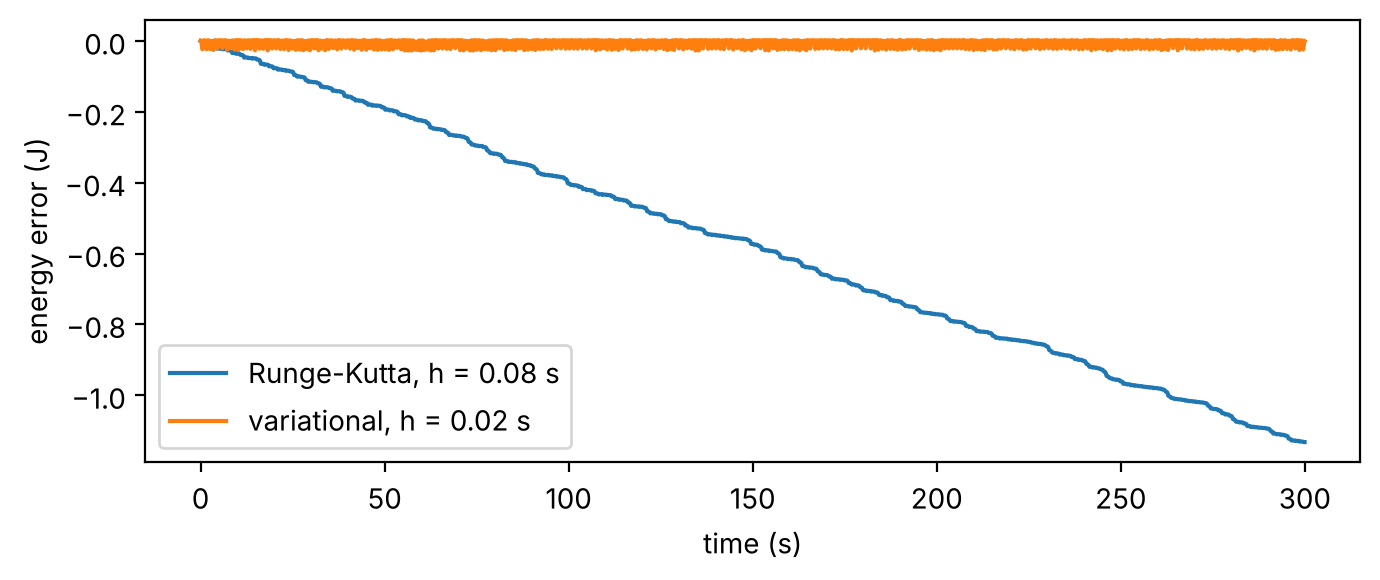

In [6]:
T = 300.0
R, p = R0.copy(), J @ Om0
dE_vi, pi3 = [], []
for k in range(int(T / 0.02)):
    R, p = lgvi_step(R, p, 0.02)
    dE_vi.append(energy_3d(R, p) - E0)
    pi3.append(E3 @ R @ p)
print(f"variational, h = 0.02: |R'R - I| = {np.linalg.norm(R.T @ R - I3):.1e},"
      f" e3.Rp moved by {np.ptp(pi3):.1e}, energy band {np.abs(dE_vi).max():.4f} J")
R, Om = R0.copy(), Om0.copy()
dE_rk = []
for k in range(int(T / 0.08)):
    R, Om = rk4_step(R, Om, 0.08)
    dE_rk.append(energy_3d(R, J @ Om) - E0)
print(f"Runge-Kutta, h = 0.08: |R'R - I| = {np.linalg.norm(R.T @ R - I3):.1e},"
      f" energy change {dE_rk[-1]:.3f} J")
plt.figure(figsize=(7, 3))
plt.plot(0.08 * np.arange(len(dE_rk)), dE_rk, label="Runge-Kutta, h = 0.08 s")
plt.plot(0.02 * np.arange(len(dE_vi)), dE_vi, label="variational, h = 0.02 s")
plt.xlabel("time (s)")
plt.ylabel("energy error (J)")
plt.legend()
plt.tight_layout()
plt.show()

The derivation, checked. The discrete Lagrangian is
$L_h = \tfrac1h \operatorname{tr}\big((I - R_k^\top R_{k+1})\bar J\big)
 - \tfrac h2\, m g\, e_3\cdot(R_k\rho + R_{k+1}\rho)$ with
$\bar J = \tfrac12\operatorname{tr}(J) I - J$. Along a computed trajectory, the action
sum must not change to first order when an interior attitude is rotated.

In [7]:
Jbar = 0.5 * np.trace(J) * I3 - J


def L_h(Ra, Rb, h):
    return (np.trace((I3 - Ra.T @ Rb) @ Jbar) / h
            - 0.5 * h * m_p * G * E3 @ (Ra @ rho + Rb @ rho))


h = 0.02
Rs, ps = [R0], [J @ Om0]
for k in range(4):
    R1, p1 = lgvi_step(Rs[-1], ps[-1], h)
    Rs.append(R1)
    ps.append(p1)
eps = 1e-6
k = 2
slope = [(L_h(Rs[k - 1], Rs[k] @ expm_so3(eps * e), h) + L_h(Rs[k] @ expm_so3(eps * e), Rs[k + 1], h)
          - L_h(Rs[k - 1], Rs[k] @ expm_so3(-eps * e), h) - L_h(Rs[k] @ expm_so3(-eps * e), Rs[k + 1], h))
         / (2 * eps) for e in I3]
print("slope of the action sum at R_2:", np.array(slope))
mom = [-(L_h(Rs[k] @ expm_so3(eps * e), Rs[k + 1], h) - L_h(Rs[k] @ expm_so3(-eps * e), Rs[k + 1], h))
       / (2 * eps) for e in I3]
print("minus slope in the first slot:", np.array(mom), " p_2:", ps[k])

slope of the action sum at R_2: [ 6.15826834e-10  1.31838984e-09 -4.23272528e-10]
minus slope in the first slot: [-0.12230102  0.15020545  0.60033597]  p_2: [-0.12230102  0.15020545  0.60033597]


## 4. A biped made of three rotations

The explicit exponential update, $p_{k+1} = \Upsilon_k^\top p_k + h\,\tau_{k+1}$ with
$\Upsilon_k = \exp(h\,(J^{-1}p_k)^\wedge)$, on the same uncontrolled pendulum. It stays
on the group and conserves $e_3\cdot R_k p_k$, and its energy drifts in proportion to $h$.

In [8]:
def explicit_update(R, p, h):
    U = expm_so3(h * J_inv @ p)
    R1 = R @ U
    return R1, U.T @ p + h * torque(R1)


for h in (0.02, 0.01, 0.005):
    R, p = R0.copy(), J @ Om0
    for k in range(int(60 / h)):
        R, p = explicit_update(R, p, h)
    print(f"h = {h:5.3f}: energy gain after 60 s = {energy_3d(R, p) - E0:7.2f} J,"
          f" |R'R - I| = {np.linalg.norm(R.T @ R - I3):.1e},"
          f" e3.Rp change = {E3 @ R @ p - E3 @ R0 @ J @ Om0:.1e}")

h = 0.020: energy gain after 60 s =  107.86 J, |R'R - I| = 1.4e-14, e3.Rp change = -3.6e-15
h = 0.010: energy gain after 60 s =   50.24 J, |R'R - I| = 1.2e-14, e3.Rp change = -6.3e-15


h = 0.005: energy gain after 60 s =   22.43 J, |R'R - I| = 3.4e-14, e3.Rp change = 1.8e-15


## 5. The sphere

The spherical pendulum, $m = l = 1$. Kick, turn, kick.

In [9]:
def s2_step(q, p, h):
    pb = p - 0.5 * h * G * np.cross(q, E3)
    w = h * pb
    q1 = np.cross(w, q) + np.sqrt(1 - w @ w) * q
    return q1, pb - 0.5 * h * G * np.cross(q1, E3)


q = np.array([np.sin(1.0), 0.0, -np.cos(1.0)])
p = np.cross(q, np.array([0.0, 1.6, 0.0]))
E0s, pz0 = 0.5 * p @ p + G * E3 @ q, E3 @ p
band = 0.0
for k in range(20000):
    q, p = s2_step(q, p, 0.01)
    band = max(band, abs(0.5 * p @ p + G * E3 @ q - E0s))
print(f"|q|^2 - 1 = {q @ q - 1:.1e}, e3.p change = {E3 @ p - pz0:.1e}, energy band {band:.2e} J")

|q|^2 - 1 = 2.4e-14, e3.p change = 0.0e+00, energy band 1.17e-03 J


## 6. Dynamics as constraints

Collocation defects of the exact solution of $\dot x = x(1-x)$, and the midpoint of two
rotations taken entry by entry.

In [10]:
f = lambda x: x * (1 - x)
sol = lambda t: 1 / (1 + 9 * np.exp(-t))
for hh in (0.2, 0.1):
    xa, xb = sol(3.0), sol(3.0 + hh)
    trap = xb - xa - 0.5 * hh * (f(xa) + f(xb))
    xm = 0.5 * (xa + xb) + hh / 8 * (f(xa) - f(xb))
    hs = xb - xa - hh / 6 * (f(xa) + 4 * f(xm) + f(xb))
    print(f"h = {hh}: trapezoidal defect {trap:.2e}, Hermite-Simpson defect {hs:.2e}")
Ra, Rb = I3, expm_so3(np.radians(90) * np.array([0.6, 0.0, 0.8]))
Mid = 0.5 * (Ra + Rb)
print("entrywise midpoint: singular values", np.round(np.linalg.svd(Mid)[1], 3),
      " det", round(np.linalg.det(Mid), 3))

h = 0.2: trapezoidal defect 3.17e-05, Hermite-Simpson defect -2.75e-08
h = 0.1: trapezoidal defect 4.49e-06, Hermite-Simpson defect -8.79e-10
entrywise midpoint: singular values [1.    0.707 0.707]  det 0.5


A 150° rest-to-rest turn with $|\tau_i| \le 0.5$ N·m, $N = 20$, $h = 0.1$ s, transcribed
two ways and solved with SLSQP: trapezoidal collocation in the exponential chart
$R = \exp(\eta^\wedge)$ with exact kinematics, and the variational constraints with the
step velocities $\Omega_k$ as unknowns. Each plan is then replayed by a fine integrator.

chart:       62 iterations, cost 0.1614, residual 1.3e-12, miss on replay 0.45 deg


variational: 60 iterations, cost 0.1572, residual 2.3e-12, miss on replay 1.44 deg


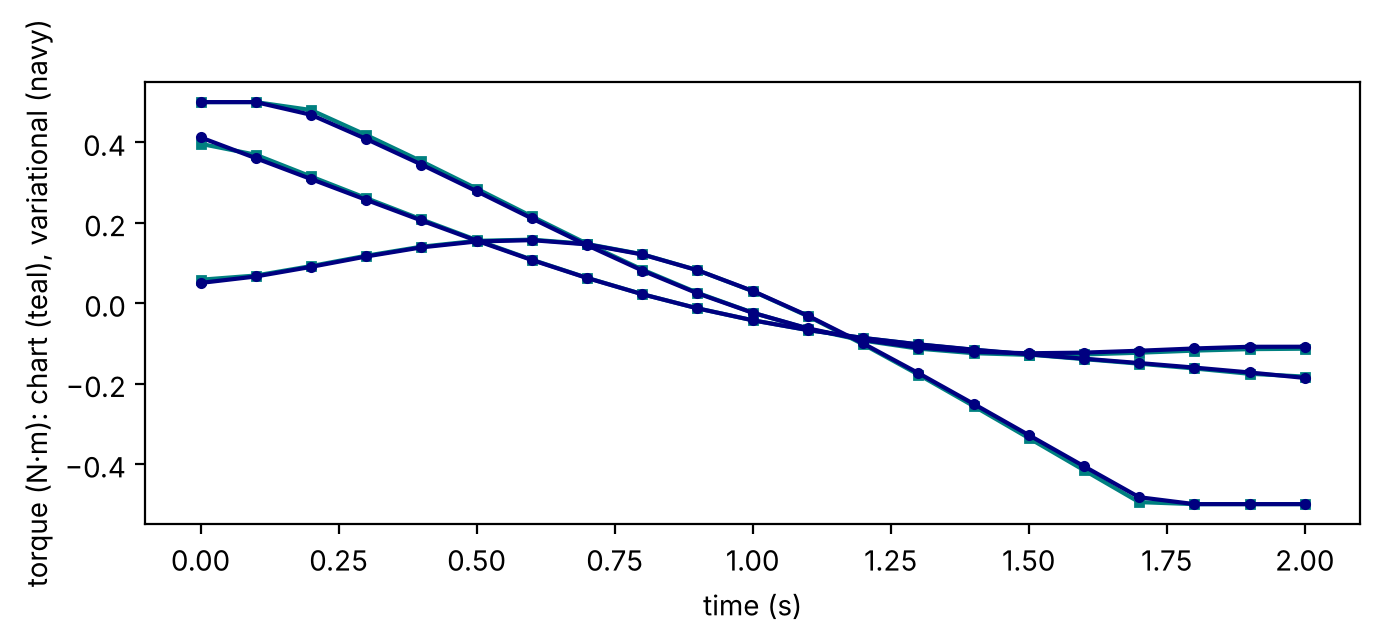

In [11]:
N, h, tau_max = 20, 0.1, 0.5
axis = np.ones(3) / np.sqrt(3)
ang = np.radians(150.0)
Rf = expm_so3(ang * axis)
wts = np.full(N + 1, h)
wts[0] = wts[-1] = h / 2
cost = lambda tau: 0.5 * np.sum(wts[:, None] * tau**2)


def cons_chart(z):
    z = z.reshape(N + 1, 9)
    eta, Om, tau = z[:, :3], z[:, 3:6], z[:, 6:]
    ed = np.array([dexpinv(eta[k], Om[k]) for k in range(N + 1)])
    fd = np.array([tau[k] - np.cross(Om[k], J @ Om[k]) for k in range(N + 1)])
    return np.concatenate([(eta[1:] - eta[:-1] - 0.5 * h * (ed[1:] + ed[:-1])).ravel(),
                           ((Om[1:] - Om[:-1]) @ J - 0.5 * h * (fd[1:] + fd[:-1])).ravel(),
                           eta[0], Om[0], Om[-1], log_so3(Rf.T @ expm_so3(eta[-1]))])


def rollout(Om):
    R = [I3]
    for k in range(N):
        R.append(R[-1] @ expm_so3(h * Om[k]))
    return R


def cons_vi(z):
    Om, tau = z[:3 * N].reshape(N, 3), z[3 * N:].reshape(N + 1, 3)
    R = rollout(Om)
    g = [step_momentum(Om[k], h) for k in range(N)]
    c = [g[0] - 0.5 * h * tau[0]]
    for k in range(1, N):
        c.append(g[k] - (R[k - 1].T @ R[k]).T @ g[k - 1] - h * tau[k])
    c.append((R[N - 1].T @ R[N]).T @ g[N - 1] + 0.5 * h * tau[N])
    c.append(log_so3(Rf.T @ R[N]))
    return np.concatenate(c)


def replay(tau, n_sub=100):
    R, Om, hs = I3.copy(), np.zeros(3), h / n_sub
    for k in range(N):
        for j in range(n_sub):
            def fr(th, Om_, s):
                tq = tau[k] + (tau[k + 1] - tau[k]) * (j + s) / n_sub
                return dexpinv(th, Om_), J_inv @ (tq - np.cross(Om_, J @ Om_))
            z = np.zeros(3)
            k1 = fr(z, Om, 0.0)
            k2 = fr(hs / 2 * k1[0], Om + hs / 2 * k1[1], 0.5)
            k3 = fr(hs / 2 * k2[0], Om + hs / 2 * k2[1], 0.5)
            k4 = fr(hs * k3[0], Om + hs * k3[1], 1.0)
            R = R @ expm_so3(hs / 6 * (k1[0] + 2 * k2[0] + 2 * k3[0] + k4[0]))
            Om = Om + hs / 6 * (k1[1] + 2 * k2[1] + 2 * k3[1] + k4[1])
    return np.degrees(np.linalg.norm(log_so3(Rf.T @ R)))


rate = np.tile(ang * axis / (N * h), (N + 1, 1))
rate[0] = rate[-1] = 0
z0_chart = np.hstack([np.outer(np.linspace(0, 1, N + 1), ang * axis), rate, np.zeros((N + 1, 3))]).ravel()
bnd_chart = [(None, None)] * 6 + [(-tau_max, tau_max)] * 3
res = minimize(lambda z: cost(z.reshape(N + 1, 9)[:, 6:]), z0_chart, method="SLSQP",
               constraints=[{"type": "eq", "fun": cons_chart}], bounds=bnd_chart * (N + 1),
               options={"maxiter": 500, "ftol": 1e-10})
tau_chart = res.x.reshape(N + 1, 9)[:, 6:]
print(f"chart:       {res.nit} iterations, cost {res.fun:.4f},"
      f" residual {np.abs(cons_chart(res.x)).max():.1e}, miss on replay {replay(tau_chart):.2f} deg")

z0_vi = np.concatenate([np.tile(ang * axis / (N * h), N), np.zeros(3 * (N + 1))])
bnd_vi = [(None, None)] * (3 * N) + [(-tau_max, tau_max)] * (3 * (N + 1))
res = minimize(lambda z: cost(z[3 * N:].reshape(N + 1, 3)), z0_vi, method="SLSQP",
               constraints=[{"type": "eq", "fun": cons_vi}], bounds=bnd_vi,
               options={"maxiter": 500, "ftol": 1e-10})
tau_vi = res.x[3 * N:].reshape(N + 1, 3)
print(f"variational: {res.nit} iterations, cost {res.fun:.4f},"
      f" residual {np.abs(cons_vi(res.x)).max():.1e}, miss on replay {replay(tau_vi):.2f} deg")
plt.figure(figsize=(7, 3))
tt = h * np.arange(N + 1)
plt.plot(tt, tau_chart, "s-", ms=3, color="teal")
plt.plot(tt, tau_vi, "o-", ms=3, color="navy")
plt.xlabel("time (s)")
plt.ylabel("torque (N·m): chart (teal), variational (navy)")
plt.tight_layout()
plt.show()

## Starting points for the exercises

- **Symplectic Euler.** Change `verlet` into the step of the one-sided discrete
  Lagrangian (full kick with the force at the new angle) and compare energy bands.
- **Modified energy.** Raise `h` in the determinant cell until $1 - h^2 g/4l$ changes
  sign, and watch what `np.linalg.eigvals(M_ver)` does.
- **Vector form.** Check `step_momentum(Om, h)` against
  `vee(U @ Jbar - Jbar @ U.T) / h` with `U = expm_so3(h * Om)` at random `Om`.
- **Noether.** In the five-minute run, also record all three components of `R @ p`.
  Which one stays constant, and which symmetry of `L_h` is responsible?
- **Explicit update.** Rerun the explicit update from rest (`Om0 = 0`) and with spin.
  Then replace `J_inv @ p` in `explicit_update` by `solve_step(p, h)`.
- **Transcription.** Set `N = 40` and `h = 0.05` in the last cell and compare the two
  misses. Then move the target to 350° and look at `np.linalg.norm(eta, axis=1)`.

In [12]:
Om = np.array([0.4, -1.2, 2.0])
U = expm_so3(0.1 * Om)
print("vector form minus matrix form:", step_momentum(Om, 0.1) - vee(U @ Jbar - Jbar @ U.T) / 0.1)

vector form minus matrix form: [ 0.00000000e+00  5.55111512e-17 -8.32667268e-17]
